# TP2 — Auto-encodeurs, VAE, CVAE et PixelCNN
**Amjad AAYD et [information masquée] — [information masquée]**
Ce notebook suit les quatre blocs du PDF de [information masquée].
Chaque bloc explique le but, la méthode et les limites des résultats observés.
Les figures proviennent uniquement des modèles réellement entraînés ici.

## Comment lire le code et comprendre les résultats

Pour chaque manipulation, lire **le but**, puis les **commentaires placés avant
le code**, puis sa **sortie réelle**. Ne pas interpréter une perte avant de savoir
quelle quantité elle mesure.

- **Tenseur** : tableau de nombres. Un lot d'images a la forme `[B, 1, 28, 28]` :
  B images, 1 canal gris, 28 lignes, 28 colonnes.
- **DataLoader** : découpe les images en petits lots, mélangés pendant l'apprentissage.
- **Époque** : un passage complet sur les images d'apprentissage sélectionnées.
- **forward** : le réseau calcule sa sortie avec ses poids actuels.
- **Perte** : nombre qui indique l'erreur. `backward()` calcule les gradients ;
  `Adam.step()` ajuste les poids pour réduire cette erreur.
- **train / eval** : indiquent le mode du modèle. `no_grad()` évite de construire
  des gradients lorsqu'on affiche ou évalue, ce qui économise la mémoire.
- **Latent z** : résumé numérique de l'image. Il ne correspond pas directement
  à une étiquette et chaque composante n'a pas forcément un sens interprétable.
- **MSE** : erreur carrée moyenne entre pixels. Plus petite signifie meilleure
  reconstruction selon ce critère, pas nécessairement image plus réaliste.
- **BCE** : mesure utilisée ici pour la reconstruction du VAE sur des intensités
  entre 0 et 1. **KL** : pénalité qui rapproche les distributions latentes du prior.
- **μ et logvar** : moyenne et logarithme de variance du code probabiliste.
  On utilise le logarithme pour pouvoir produire toute valeur réelle sans variance négative.
- **One-hot** : dix cases, une seule vaut 1. Pour le chiffre 3 : la case d'indice 3
  vaut 1 et les neuf autres valent 0.
- **Logits** : scores avant transformation en probabilités. PixelCNN donne 256
  scores par pixel ; `softmax` donne les probabilités et `multinomial` tire une valeur.
- **Test** : images absentes des mises à jour des poids. Les mesures test servent
  à vérifier ce que le modèle fait sur des exemples qu'il n'a pas appris directement.

**Comment a-t-on trouvé les résultats ?** Nous chargeons les vraies données,
entraînons les réseaux, calculons les mesures avec leurs sorties, puis sauvegardons
les figures et nombres. Aucun chiffre de performance n'est rempli à la main.


PyTorch : 2.12.0.dev20260408+cu128 | torchvision : 0.27.0.dev20260407+cu128
Matériel : NVIDIA GeForce RTX 5070 Ti Laptop GPU
Dossier : C:\Users\amjad\Documents\Codex\2026-10-07\do-th\outputs\TP2_AE_VAE
FashionMNIST : 60000 train / 10000 test
MNIST : 60000 train / 10000 test


Forme image : (1, 28, 28) | intervalle : 0.0 1.0


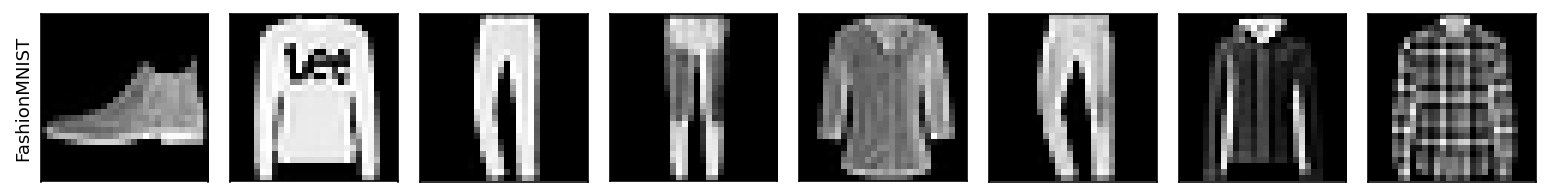

In [1]:
# Préparer un calcul reproductible et choisir le GPU réellement disponible.
# Les graines stabilisent les tirages ; CUDA peut néanmoins varier légèrement.
import os, json, time, random
from pathlib import Path
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset
import torchvision
from torchvision.datasets import FashionMNIST, MNIST
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image
from sklearn.manifold import TSNE
ROOT = Path.cwd()
for folder in ['figures','models','data']:
    (ROOT/folder).mkdir(exist_ok=True)
random.seed(42); np.random.seed(42); torch.manual_seed(42)
torch.set_num_threads(6)
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch :',torch.__version__,'| torchvision :',torchvision.__version__)
print('Matériel :',torch.cuda.get_device_name(0) if device.type=='cuda' else 'CPU')
print('Dossier :',ROOT)
metrics={}; histories={}; started=time.time()

# Charger les vraies bases officielles : aucun remplacement synthétique.
# Les 60 000 images d'apprentissage sont utilisées, sauf PixelCNN (12 000,
# choix explicitement signalé pour limiter son coût). Test = 10 000 images.
fashion_train=FashionMNIST(str(ROOT/'data'),train=True,download=True)
fashion_test=FashionMNIST(str(ROOT/'data'),train=False,download=True)
digit_train=MNIST(str(ROOT/'data'),train=True,download=True)
digit_test=MNIST(str(ROOT/'data'),train=False,download=True)
def tensors(ds):
    # Convertir les octets 0–255 en intensités flottantes 0–1, avec un canal.
    return ds.data.unsqueeze(1).float().div(255),ds.targets.long()
fx,fy=tensors(fashion_train); ft,fty=tensors(fashion_test)
mx,my=tensors(digit_train); mt,mty=tensors(digit_test)
fl=DataLoader(TensorDataset(fx,fy),batch_size=256,shuffle=True)
ml=DataLoader(TensorDataset(mx,my),batch_size=256,shuffle=True)
print('FashionMNIST :',len(fx),'train /',len(ft),'test')
print('MNIST :',len(mx),'train /',len(mt),'test')
print('Forme image :',tuple(fx[0].shape),'| intervalle :',float(fx.min()),float(fx.max()))

# Enregistrer chaque figure, puis l'afficher dans le notebook exécuté.
def savefig(name):
    plt.tight_layout(); path=ROOT/'figures'/f'{name}.png'
    plt.savefig(path,dpi=145,bbox_inches='tight'); plt.close()
    display(Image(filename=str(path)))
def grid(rows,labels,name,n=8):
    # Une colonne représente le même exemple dans les différentes lignes.
    fig,axes=plt.subplots(len(rows),n,figsize=(n*1.35,len(rows)*1.55),squeeze=False)
    for r,values in enumerate(rows):
        for j in range(n):
            axes[r,j].imshow(values[j].detach().cpu().squeeze(),cmap='gray',vmin=0,vmax=1)
            axes[r,j].set_xticks([]);axes[r,j].set_yticks([])
            if j==0:axes[r,j].set_ylabel(labels[r],fontsize=9)
    savefig(name)
def curves(hist,name):
    # Les courbes montrent les pertes moyennes réellement mesurées à chaque époque.
    plt.figure(figsize=(7,3.5))
    for key in hist[0]:plt.plot(range(1,len(hist)+1),[r[key] for r in hist],label=key)
    plt.xlabel('Époque');plt.ylabel('Perte moyenne');plt.legend();plt.grid(alpha=.2);savefig(name)
grid([ft[:8]],['FashionMNIST'],'01_entrees')

## Bloc A1 — AE dense : compresser puis reconstruire
L'encodeur transforme 784 pixels en 128 nombres. Le décodeur essaie de retrouver
l'image d'origine. La MSE pénalise l'écart carré entre chaque pixel reconstruit
et son vrai pixel. L'architecture dense suit exactement les tailles du PDF.

AE_dense époque 1 / 10 MSE = 0.039342


AE_dense époque 2 / 10 MSE = 0.020404


AE_dense époque 3 / 10 MSE = 0.016987


AE_dense époque 4 / 10 MSE = 0.014944


AE_dense époque 5 / 10 MSE = 0.013496


AE_dense époque 6 / 10 MSE = 0.012491


AE_dense époque 7 / 10 MSE = 0.011786


AE_dense époque 8 / 10 MSE = 0.01124


AE_dense époque 9 / 10 MSE = 0.010739


AE_dense époque 10 / 10 MSE = 0.010341


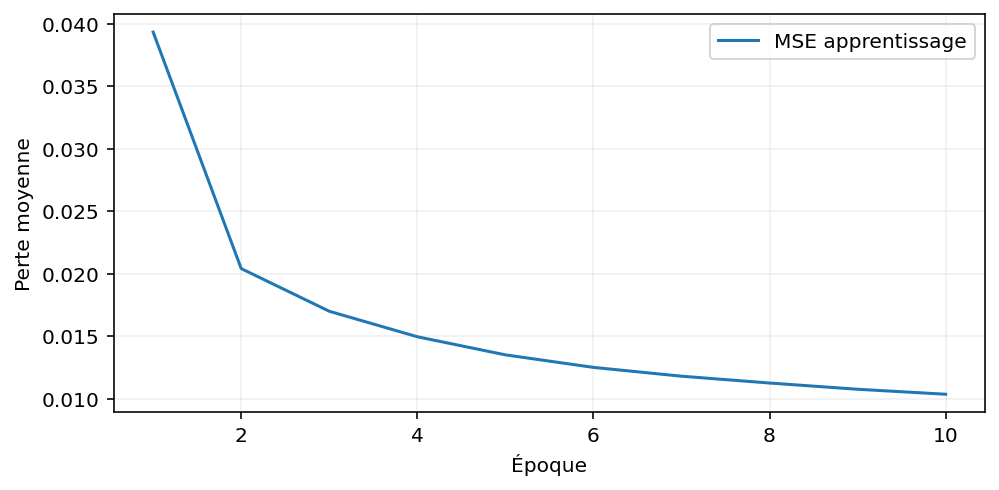

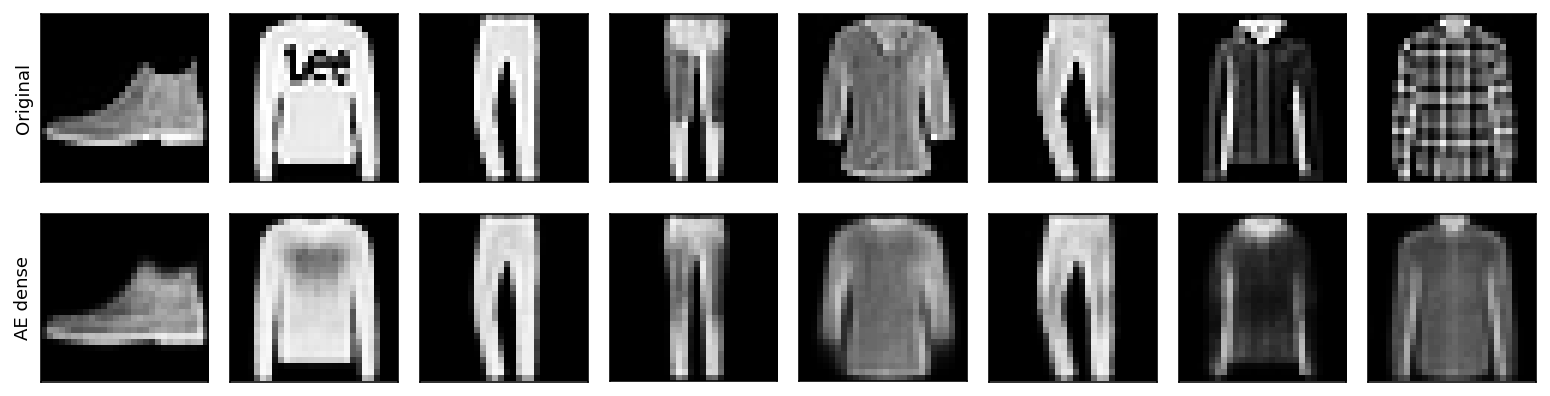

MSE test AE dense : 0.010390885211010368


In [2]:
class DenseAE(nn.Module):
    def __init__(self):
        super().__init__()
        # Aplatir 1×28×28 en 784 ; réduire ensuite à un code de taille 128.
        self.enc=nn.Sequential(nn.Flatten(),nn.Linear(784,1024),nn.ReLU(),nn.Linear(1024,256),nn.ReLU(),nn.Linear(256,128))
        # La sigmoïde produit des intensités entre zéro et un.
        self.dec=nn.Sequential(nn.Linear(128,256),nn.ReLU(),nn.Linear(256,1024),nn.ReLU(),nn.Linear(1024,784),nn.Sigmoid(),nn.Unflatten(1,(1,28,28)))
    def forward(self,x):return self.dec(self.enc(x))

def train_ae(model,name,epochs=10,noise=0):
    # Pour un DAE, seule l'entrée est bruitée : la cible reste toujours propre.
    model.to(device);opt=torch.optim.Adam(model.parameters(),lr=1e-3);hist=[]
    for ep in range(epochs):
        model.train();total=0
        for x,_ in fl:
            x=x.to(device);inp=(x+noise*torch.randn_like(x)).clamp(0,1) if noise else x
            # Effacer les gradients du lot précédent pour ne pas les additionner.
            opt.zero_grad(set_to_none=True)
            # Reconstruire l'entrée, puis comparer chaque pixel à la cible propre.
            loss=F.mse_loss(model(inp),x)
            # Calculer comment chaque poids contribue à l'erreur.
            loss.backward()
            # Adam met à jour les poids ; accumuler ensuite l'erreur de cette époque.
            opt.step()
            total+=loss.item()*len(x)
        hist.append({'MSE apprentissage':total/len(fx)})
        print(name,'époque',ep+1,'/',epochs,'MSE =',round(total/len(fx),6),flush=True)
    model.eval();histories[name]=hist;torch.save(model.state_dict(),ROOT/'models'/f'{name}.pt')
    return model
@torch.no_grad()
def ae_mse(model,noise=0):
    # Évaluer sur tout le test, jamais utilisé pour les mises à jour du modèle.
    total=0
    gen=torch.Generator().manual_seed(123)
    for x in ft.split(256):
        noisy=(x+noise*torch.randn(x.shape,generator=gen)).clamp(0,1) if noise else x
        pred=model(noisy.to(device)).cpu();total+=F.mse_loss(pred,x,reduction='sum').item()
    return total/ft.numel()
dense=train_ae(DenseAE(),'AE_dense')
metrics['AE_dense_test_MSE']=ae_mse(dense)
curves(histories['AE_dense'],'02_dense_perte')
with torch.no_grad():dense_rec=dense(ft[:8].to(device)).cpu()
grid([ft[:8],dense_rec],['Original','AE dense'],'03_dense_reconstruction')
print('MSE test AE dense :',metrics['AE_dense_test_MSE'])

## Bloc A2 — AE convolutionnel : conserver les relations spatiales
Deux convolutions stride 2 réduisent 28→14→7. Une couche linéaire forme le code
latent de 128 valeurs. Les convolutions transposées remontent 7→14→28.
Les mêmes images test permettent une comparaison qualitative avec l'AE dense.

AE_conv époque 1 / 10 MSE = 0.030877


AE_conv époque 2 / 10 MSE = 0.012835


AE_conv époque 3 / 10 MSE = 0.010061


AE_conv époque 4 / 10 MSE = 0.008491


AE_conv époque 5 / 10 MSE = 0.007522


AE_conv époque 6 / 10 MSE = 0.00684


AE_conv époque 7 / 10 MSE = 0.006314


AE_conv époque 8 / 10 MSE = 0.005907


AE_conv époque 9 / 10 MSE = 0.005555


AE_conv époque 10 / 10 MSE = 0.005303


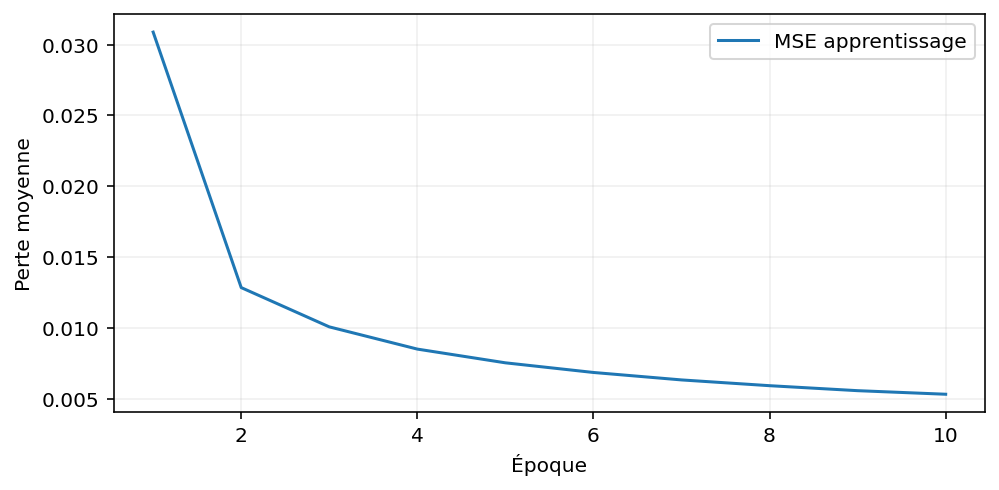

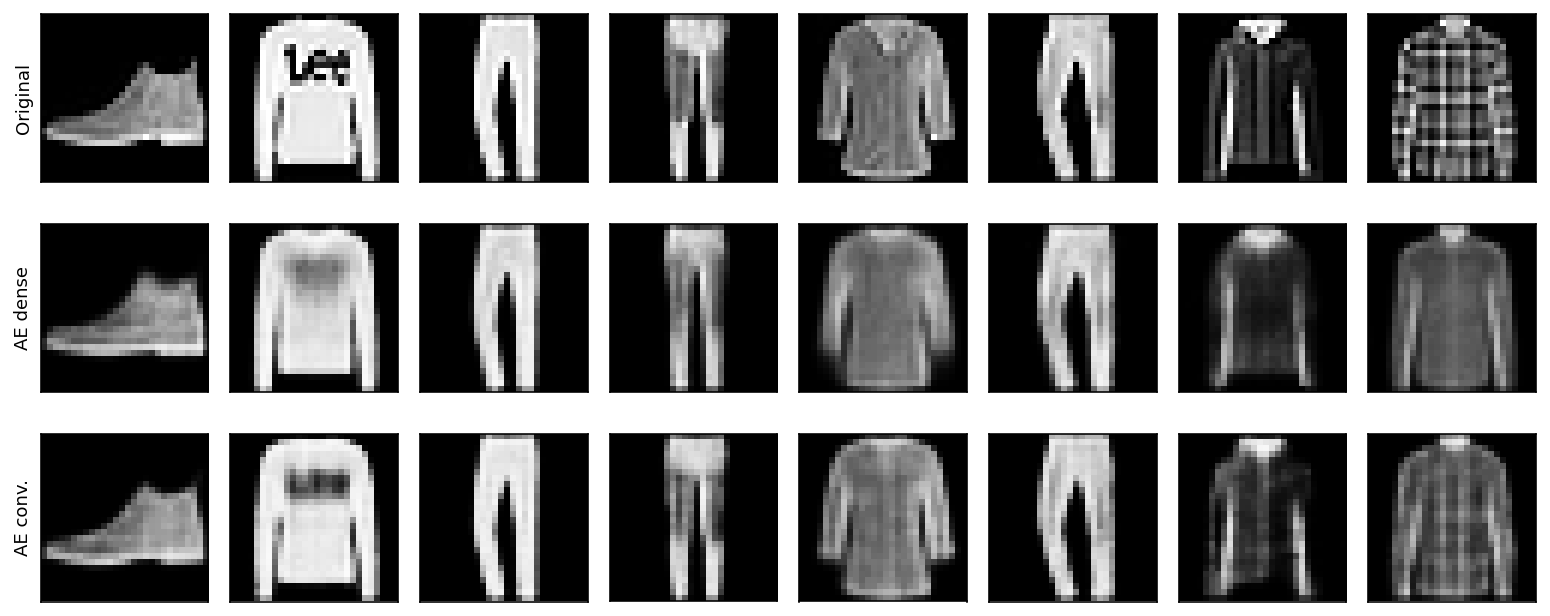

MSE test convolutionnel : 0.00526549266406468
Paramètres dense / conv : 2198928 872769


In [3]:
class ConvAE(nn.Module):
    def __init__(self):
        super().__init__()
        # Les filtres sont partagés entre positions, contrairement aux poids denses.
        self.enc=nn.Sequential(nn.Conv2d(1,32,4,2,1),nn.ReLU(),nn.Conv2d(32,64,4,2,1),nn.ReLU(),nn.Flatten(),nn.Linear(64*7*7,128))
        self.dec=nn.Sequential(nn.Linear(128,64*7*7),nn.Unflatten(1,(64,7,7)),nn.ReLU(),nn.ConvTranspose2d(64,32,4,2,1),nn.ReLU(),nn.ConvTranspose2d(32,1,4,2,1),nn.Sigmoid())
    def forward(self,x):return self.dec(self.enc(x))
conv=train_ae(ConvAE(),'AE_conv')
metrics['AE_conv_test_MSE']=ae_mse(conv)
curves(histories['AE_conv'],'04_conv_perte')
with torch.no_grad():conv_rec=conv(ft[:8].to(device)).cpu()
grid([ft[:8],dense_rec,conv_rec],['Original','AE dense','AE conv.'],'05_comparaison_AE')
print('MSE test convolutionnel :',metrics['AE_conv_test_MSE'])
print('Paramètres dense / conv :',sum(p.numel() for p in dense.parameters()),sum(p.numel() for p in conv.parameters()))

## Bloc A3 — Débruiter et interpoler
D'abord, on teste l'AE entraîné sur des images propres face à du bruit.
Ensuite, on entraîne une troisième variante : entrée bruitée, cible propre.
L'écart entre les deux montre ce que l'apprentissage explicite du débruitage apporte.
Le bruit est gaussien et les pixels sont tronqués dans [0,1], comme demandé.

DAE époque 1 / 10 MSE = 0.032044


DAE époque 2 / 10 MSE = 0.01504


DAE époque 3 / 10 MSE = 0.012756


DAE époque 4 / 10 MSE = 0.011534


DAE époque 5 / 10 MSE = 0.010774


DAE époque 6 / 10 MSE = 0.010219


DAE époque 7 / 10 MSE = 0.009824


DAE époque 8 / 10 MSE = 0.009497


DAE époque 9 / 10 MSE = 0.00925


DAE époque 10 / 10 MSE = 0.009042


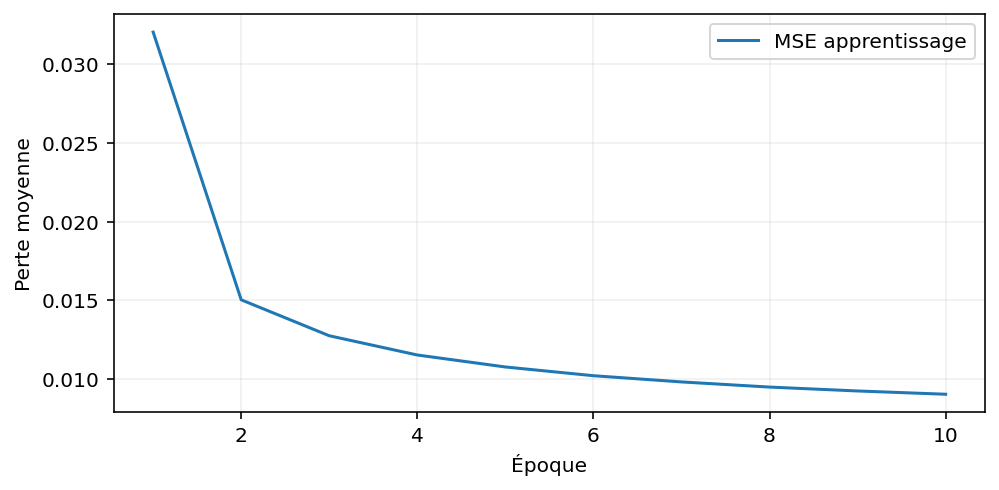

[
  {
    "sigma": 0,
    "AE_conv_MSE": 0.00526549266406468,
    "DAE_MSE": 0.008617430223737444
  },
  {
    "sigma": 0.1,
    "AE_conv_MSE": 0.00788271238365952,
    "DAE_MSE": 0.0083142812942972
  },
  {
    "sigma": 0.3,
    "AE_conv_MSE": 0.022464164453623245,
    "DAE_MSE": 0.009062609637513453
  },
  {
    "sigma": 0.5,
    "AE_conv_MSE": 0.04539314422607422,
    "DAE_MSE": 0.017737309794523277
  }
]


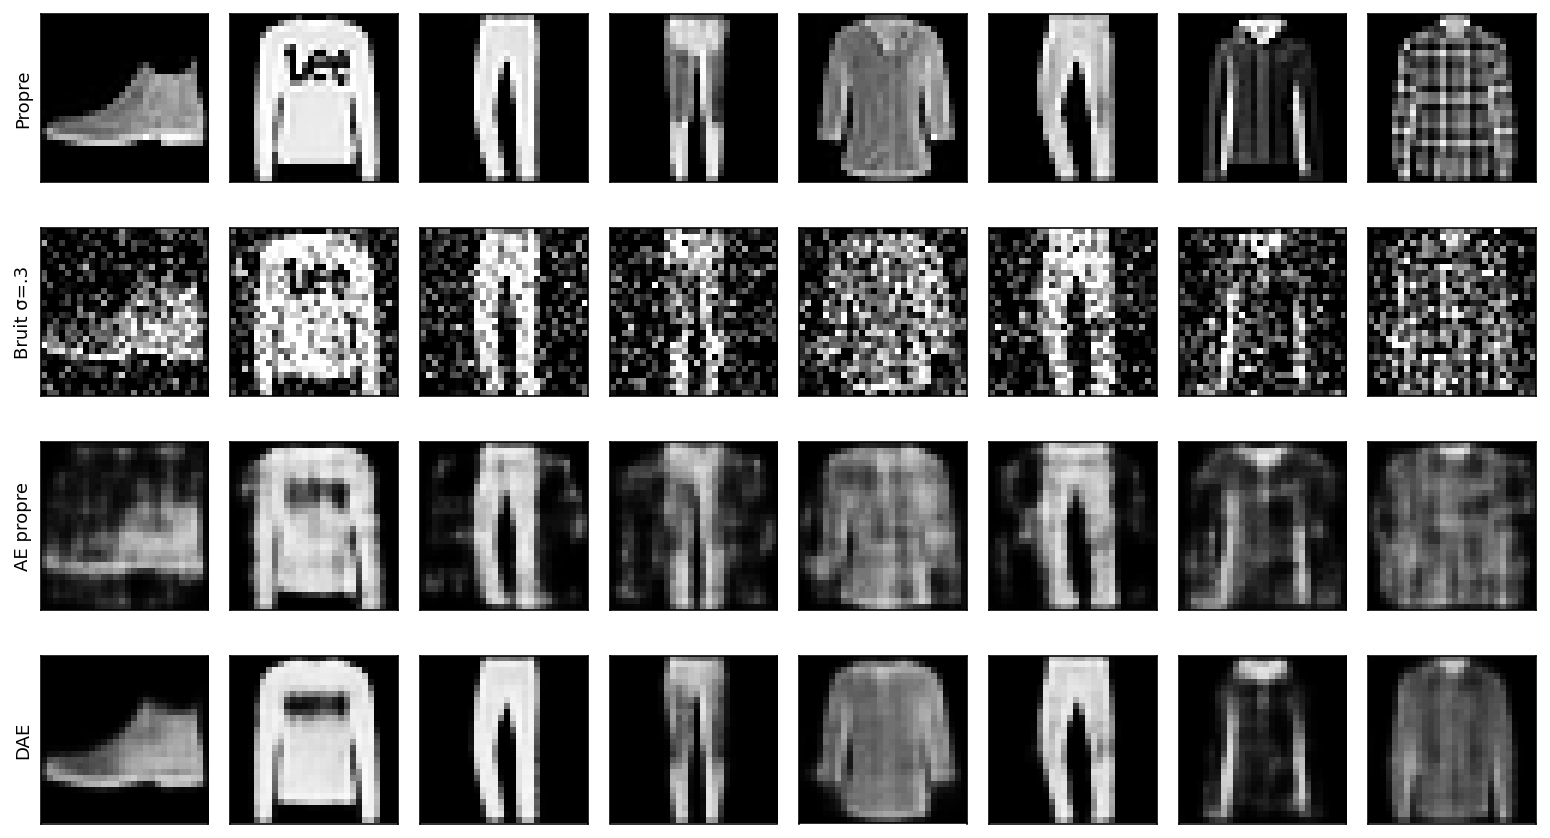

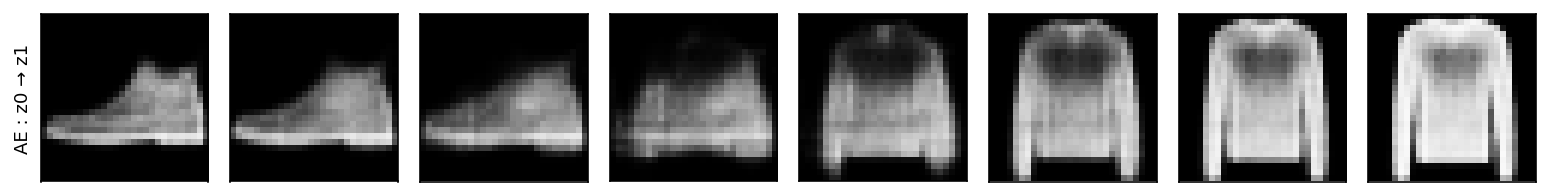

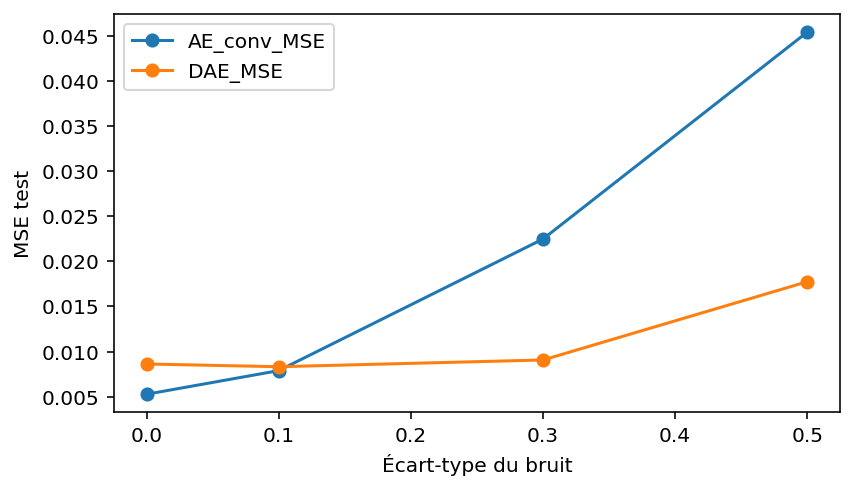

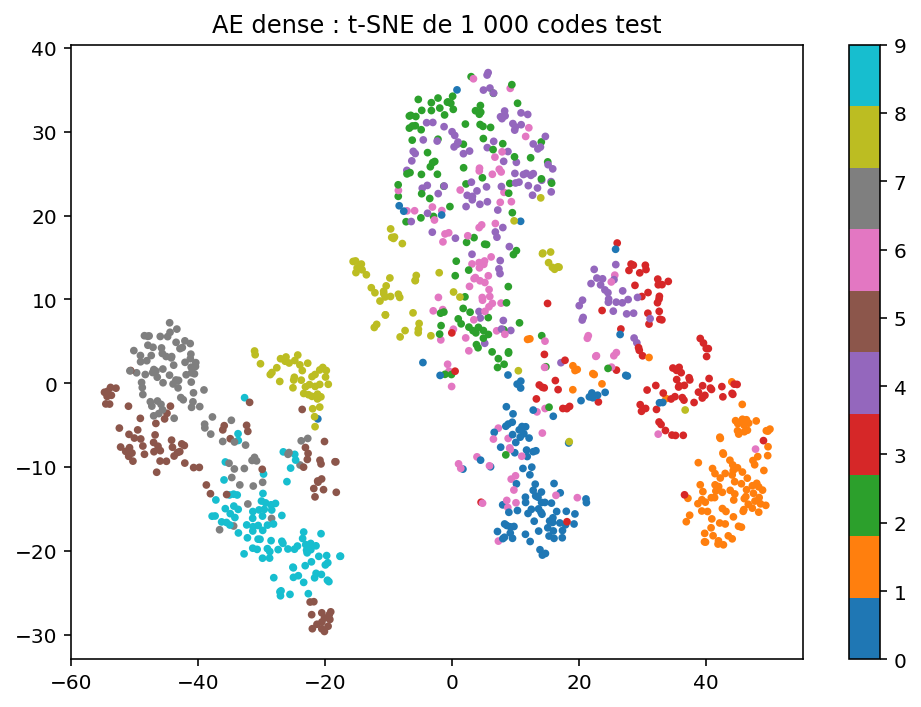

In [4]:
dae=train_ae(ConvAE(),'DAE',noise=.3)
curves(histories['DAE'],'06_DAE_perte')
noise_results=[]
for sigma in [0,.1,.3,.5]:
    # Réutiliser un bruit reproductible pour comparer les deux modèles équitablement.
    clean_error=ae_mse(conv,sigma);dae_error=ae_mse(dae,sigma)
    noise_results.append({'sigma':sigma,'AE_conv_MSE':clean_error,'DAE_MSE':dae_error})
metrics['debruitage']=noise_results
print(json.dumps(noise_results,indent=2))
torch.manual_seed(123)
noisy=(ft[:8]+.3*torch.randn_like(ft[:8])).clamp(0,1)
with torch.no_grad():
    grid([ft[:8],noisy,conv(noisy.to(device)).cpu(),dae(noisy.to(device)).cpu()],['Propre','Bruit σ=.3','AE propre','DAE'],'07_debruitage')
    z=dense.enc(ft[:2].to(device))
    # Mélanger deux codes, puis décoder : aucune interpolation directe des pixels.
    alpha=torch.linspace(0,1,8,device=device).unsqueeze(1)
    inter=dense.dec((1-alpha)*z[0]+alpha*z[1])
    grid([inter],['AE : z0 → z1'],'08_interpolation_AE')
plt.figure(figsize=(6,3.5))
for key in ['AE_conv_MSE','DAE_MSE']:plt.plot([r['sigma'] for r in noise_results],[r[key] for r in noise_results],marker='o',label=key)
plt.xlabel('Écart-type du bruit');plt.ylabel('MSE test');plt.legend();savefig('09_effet_bruit')

# Projeter seulement 1 000 codes : t-SNE coûte cher et ne conserve pas toutes les distances.
# Les couleurs sont les classes réelles ; elles ne servent pas à entraîner les AEs.
with torch.no_grad():z=dense.enc(ft[:1000].to(device)).cpu().numpy()
proj=TSNE(n_components=2,perplexity=30,init='pca',learning_rate='auto',random_state=42).fit_transform(z)
plt.figure(figsize=(7,5));sc=plt.scatter(proj[:,0],proj[:,1],c=fty[:1000],s=8,cmap='tab10');plt.colorbar(sc,ticks=range(10));plt.title('AE dense : t-SNE de 1 000 codes test');savefig('10_tsne_AE')

### Réponses A
1. La compression retient des structures fréquentes des vêtements ; une petite
perturbation peut être rejetée lors de la reconstruction. Ce comportement n'est
pas garanti : un bruit trop fort détruit de l'information. Le DAE apprend ce rejet.
2. Les convolutions exploitent le voisinage des pixels et partagent les filtres.
Cela convient aux images, sans garantir une meilleure MSE pour tout entraînement.
3. L'AE classique n'impose aucune distribution aux codes. Un segment entre deux
codes peut donc traverser une zone jamais rencontrée pendant l'apprentissage.

## Bloc B — VAE : apprendre une distribution de codes
L'encodeur produit μ et log(σ²). Le tirage z=μ+exp(logvar/2)×ε permet la
rétropropagation. La perte est BCE + KL, sommées par image puis moyennées par lot.
La KL rapproche les codes du prior N(0,I), utilisé ensuite pour générer.

VAE époque 1 / 12 {'BCE + KL': 312.1215991373698, 'BCE reconstruction': 296.50641796875, 'KL': 15.615181331268946}


VAE époque 2 / 12 {'BCE + KL': 257.82039174804686, 'BCE reconstruction': 240.38455573730468, 'KL': 17.435835690307616}


VAE époque 3 / 12 {'BCE + KL': 251.63529701334636, 'BCE reconstruction': 234.08507852376303, 'KL': 17.550217936197917}


VAE époque 4 / 12 {'BCE + KL': 248.56422539876303, 'BCE reconstruction': 230.96517854817708, 'KL': 17.599046473185222}


VAE époque 5 / 12 {'BCE + KL': 246.58292866210937, 'BCE reconstruction': 228.99739369303384, 'KL': 17.58553484700521}


VAE époque 6 / 12 {'BCE + KL': 245.16075559895833, 'BCE reconstruction': 227.58963556315103, 'KL': 17.571120103963217}


... (2 outputs left out)

VAE époque 9 / 12 {'BCE + KL': 242.70196326497395, 'BCE reconstruction': 225.11676922200522, 'KL': 17.585194006347656}


VAE époque 10 / 12 {'BCE + KL': 242.14339000651043, 'BCE reconstruction': 224.53401508789062, 'KL': 17.60937500813802}


VAE époque 11 / 12 {'BCE + KL': 241.6431206217448, 'BCE reconstruction': 224.0744471435547, 'KL': 17.568673681640625}


VAE époque 12 / 12 {'BCE + KL': 241.26715657552083, 'BCE reconstruction': 223.70482517903645, 'KL': 17.56233157043457}


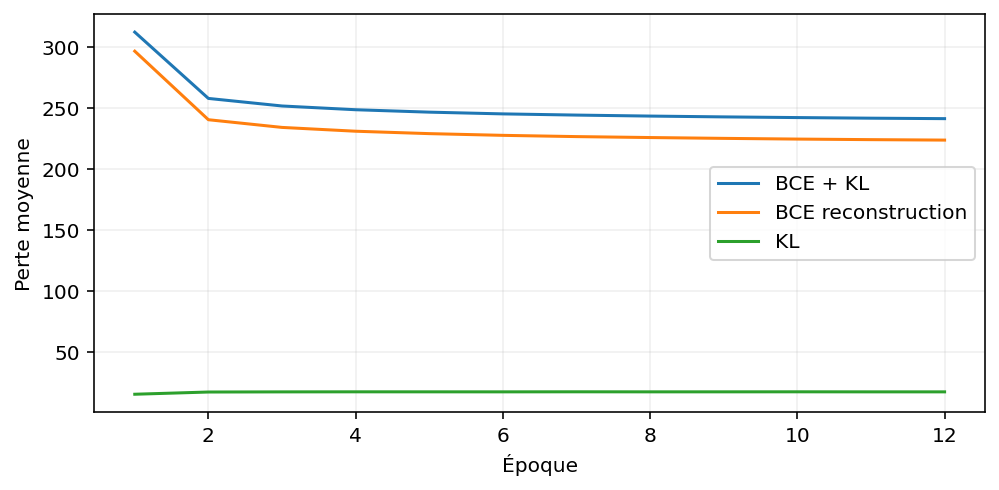

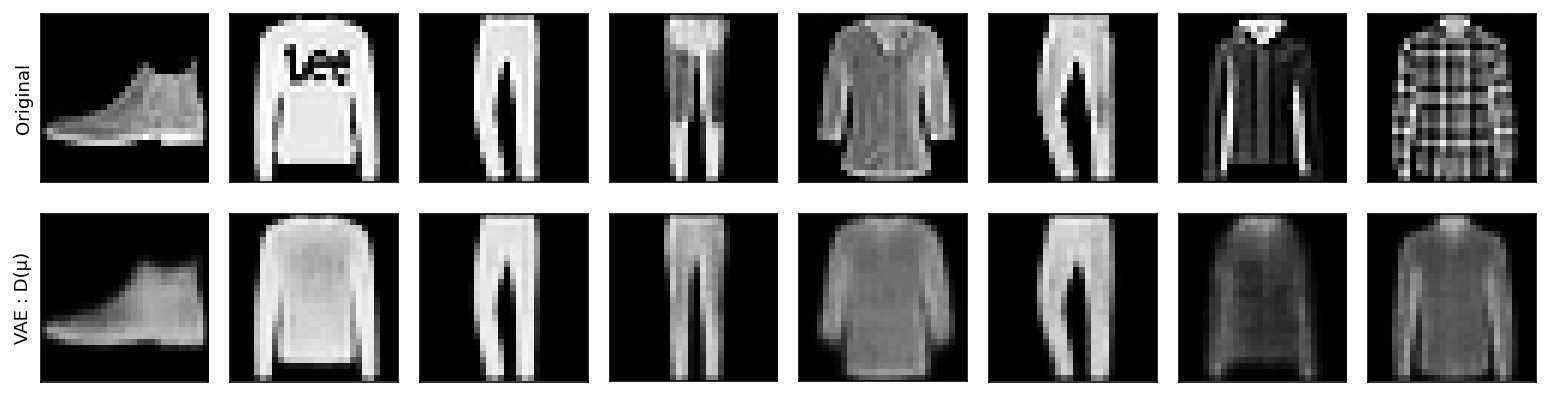

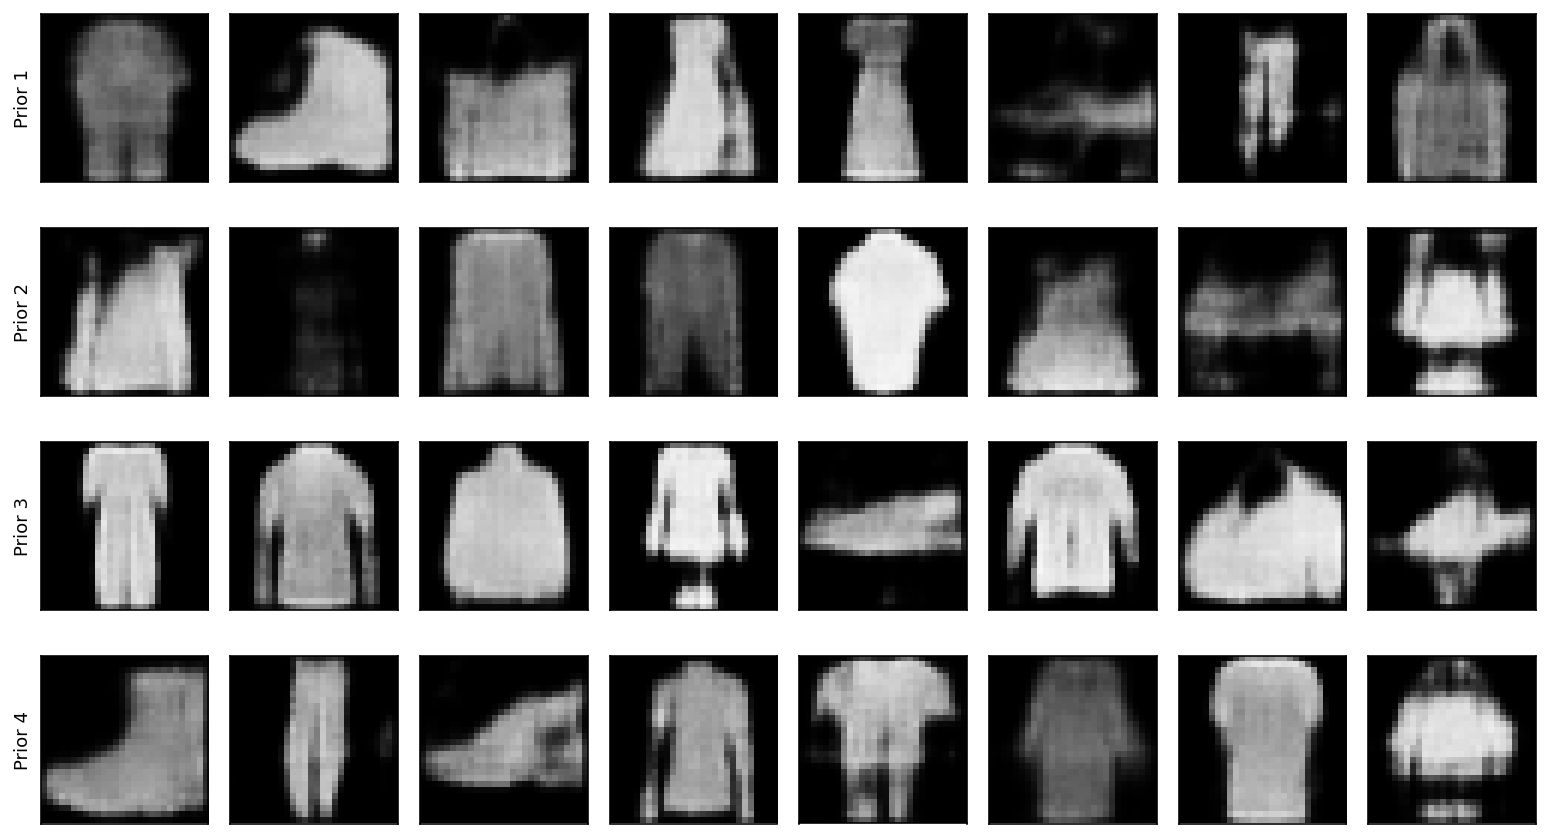

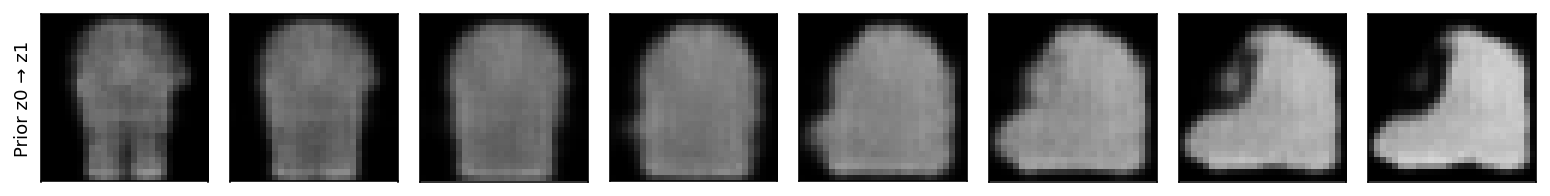

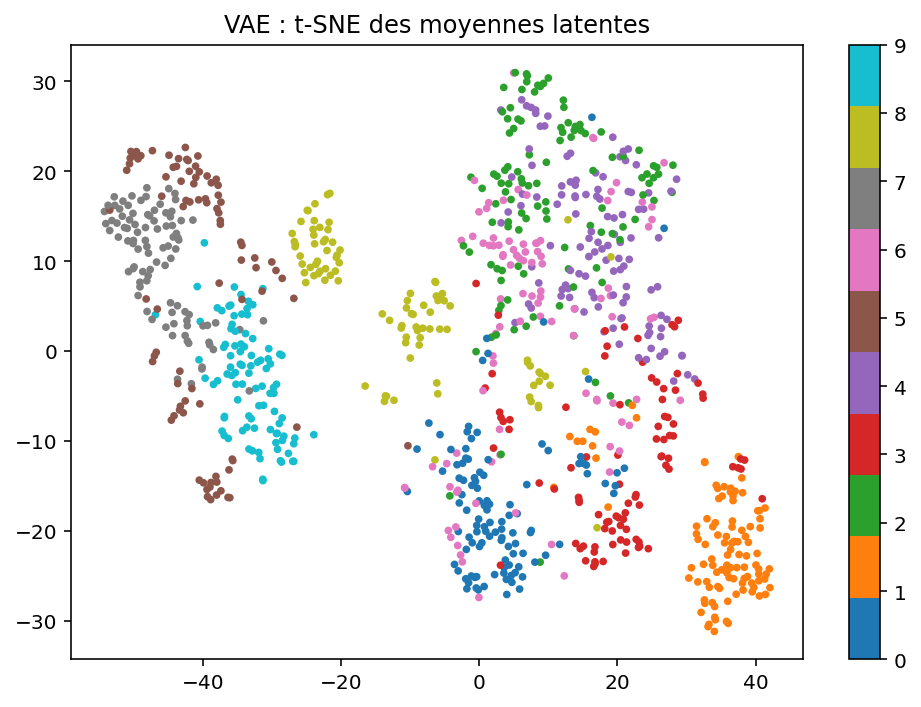

In [5]:
class VAE(nn.Module):
    def __init__(self,conditional=False,latent=16):
        super().__init__();self.conditional=conditional;self.latent=latent
        self.enc=nn.Sequential(nn.Conv2d(1,32,4,2,1),nn.ReLU(),nn.Conv2d(32,64,4,2,1),nn.ReLU(),nn.Flatten())
        # Dans le CVAE, concaténer le vecteur one-hot aux caractéristiques encodées.
        self.hidden=nn.Linear(64*7*7+(10 if conditional else 0),256)
        self.mu=nn.Linear(256,latent);self.logvar=nn.Linear(256,latent)
        self.dec=nn.Sequential(nn.Linear(latent+(10 if conditional else 0),64*7*7),nn.ReLU(),nn.Unflatten(1,(64,7,7)),nn.ConvTranspose2d(64,32,4,2,1),nn.ReLU(),nn.ConvTranspose2d(32,1,4,2,1),nn.Sigmoid())
    def encode(self,x,y=None):
        h=self.enc(x)
        if self.conditional:h=torch.cat([h,F.one_hot(y,10).float()],1)
        h=F.relu(self.hidden(h));return self.mu(h),self.logvar(h)
    def reparameterize(self,mu,logvar):
        # Le hasard vient d'epsilon ; mu et sigma restent différentiables.
        return mu+torch.exp(.5*logvar)*torch.randn_like(mu)
    def decode(self,z,y=None):
        if self.conditional:z=torch.cat([z,F.one_hot(y,10).float()],1)
        return self.dec(z)
    def forward(self,x,y=None):
        mu,logvar=self.encode(x,y);return self.decode(self.reparameterize(mu,logvar),y),mu,logvar
def vae_loss(x_rec,x,mu,logvar):
    # Les deux termes utilisent la même échelle : somme par image, moyenne du lot.
    rec=F.binary_cross_entropy(x_rec,x,reduction='sum')/len(x)
    kl=-.5*torch.sum(1+logvar-mu.square()-logvar.exp())/len(x)
    return rec+kl,rec,kl
def train_vae(model,loader,name,epochs=12):
    model.to(device);opt=torch.optim.Adam(model.parameters(),lr=1e-3);hist=[]
    for ep in range(epochs):
        model.train();tot=np.zeros(3);count=0
        for x,y in loader:
            # Copier les images et étiquettes sur le même matériel que le réseau.
            x=x.to(device);y=y.to(device)
            # Repartir de gradients nuls pour ce nouveau lot.
            opt.zero_grad(set_to_none=True)
            # Produire l'image reconstruite et les paramètres de la distribution latente.
            rec,mu,lv=model(x,y)
            # Séparer la fidélité de reconstruction et la régularisation du code.
            loss,bce,kl=vae_loss(rec,x,mu,lv)
            # Dériver la perte, puis ajuster les poids par Adam.
            loss.backward();opt.step()
            # Pondérer par le nombre d'images pour calculer une moyenne correcte.
            tot+=np.array([loss.item(),bce.item(),kl.item()])*len(x);count+=len(x)
        row=dict(zip(['BCE + KL','BCE reconstruction','KL'],(tot/count).tolist()));hist.append(row)
        print(name,'époque',ep+1,'/',epochs,row,flush=True)
    model.eval();histories[name]=hist;torch.save(model.state_dict(),ROOT/'models'/f'{name}.pt');return model
vae=train_vae(VAE(),fl,'VAE')
curves(histories['VAE'],'11_VAE_pertes')
with torch.no_grad():
    # Pour la reconstruction affichée, décoder la moyenne plutôt qu'un code aléatoire.
    mu,_=vae.encode(ft[:8].to(device));rec=vae.decode(mu)
    grid([ft[:8],rec],['Original','VAE : D(μ)'],'12_VAE_reconstruction')
    z=torch.randn(32,vae.latent,device=device)
    samples=vae.decode(z).cpu()
    grid(list(samples.reshape(4,8,1,28,28)),['Prior 1','Prior 2','Prior 3','Prior 4'],'13_VAE_generation')
    alpha=torch.linspace(0,1,8,device=device).unsqueeze(1)
    grid([vae.decode((1-alpha)*z[0]+alpha*z[1])],['Prior z0 → z1'],'14_VAE_interpolation')
    ztest=torch.cat([vae.encode(x.to(device))[0].cpu() for x in ft[:1000].split(256)])
proj=TSNE(n_components=2,perplexity=30,init='pca',learning_rate='auto',random_state=42).fit_transform(ztest.numpy())
plt.figure(figsize=(7,5));sc=plt.scatter(proj[:,0],proj[:,1],c=fty[:1000],s=8,cmap='tab10');plt.colorbar(sc,ticks=range(10));plt.title('VAE : t-SNE des moyennes latentes');savefig('15_tsne_VAE')
metrics['VAE_last_train']=histories['VAE'][-1]

### Réponses B
1. La KL empêche les distributions encodées de s'éloigner librement de N(0,I).
L'espace est ainsi mieux adapté au tirage de nouveaux codes que celui d'un AE.
2. Une KL trop forte réduit l'information disponible pour reconstruire ; une KL
trop faible laisse des régions du prior difficiles à décoder. C'est un compromis.
3. La vraisemblance pixel par pixel et la compression peuvent produire des sorties
moyennes, donc floues, lorsque plusieurs détails sont plausibles.
β est fixé à 1. L'étude optionnelle de plusieurs β n'est pas réalisée ; aucune
comparaison expérimentale entre β n'est donc revendiquée.

## Bloc C — CVAE : choisir le chiffre que l'on veut générer
MNIST remplace FashionMNIST. Le one-hot de taille 10 est injecté dans l'encodeur
ET le décodeur. À la génération, on choisit y puis tire z depuis N(0,I).
Même code z dans chaque colonne : changer la ligne ne change que la classe y.

CVAE époque 1 / 24 {'BCE + KL': 212.70183016764324, 'BCE reconstruction': 206.24904409179686, 'KL': 6.452787003552913}


CVAE époque 2 / 24 {'BCE + KL': 146.70964447428386, 'BCE reconstruction': 141.84595309244793, 'KL': 4.863691621398925}


CVAE époque 3 / 24 {'BCE + KL': 139.00614361165364, 'BCE reconstruction': 134.26741622721354, 'KL': 4.738727804056803}


CVAE époque 4 / 24 {'BCE + KL': 136.57680625813802, 'BCE reconstruction': 131.844806640625, 'KL': 4.731999511973063}


CVAE époque 5 / 24 {'BCE + KL': 135.2852062906901, 'BCE reconstruction': 130.5472514811198, 'KL': 4.73795471572876}


CVAE époque 6 / 24 {'BCE + KL': 134.34167396647135, 'BCE reconstruction': 129.61123356933595, 'KL': 4.730439717610677}


... (14 outputs left out)

CVAE époque 21 / 24 {'BCE + KL': 130.245934379069, 'BCE reconstruction': 125.51069482421875, 'KL': 4.735239161682129}


CVAE époque 22 / 24 {'BCE + KL': 130.14423146972655, 'BCE reconstruction': 125.3994736735026, 'KL': 4.744757580820719}


CVAE époque 23 / 24 {'BCE + KL': 130.0116262858073, 'BCE reconstruction': 125.25909943847657, 'KL': 4.7525268681844075}


CVAE époque 24 / 24 {'BCE + KL': 129.9115512532552, 'BCE reconstruction': 125.15295286865235, 'KL': 4.758598508961995}


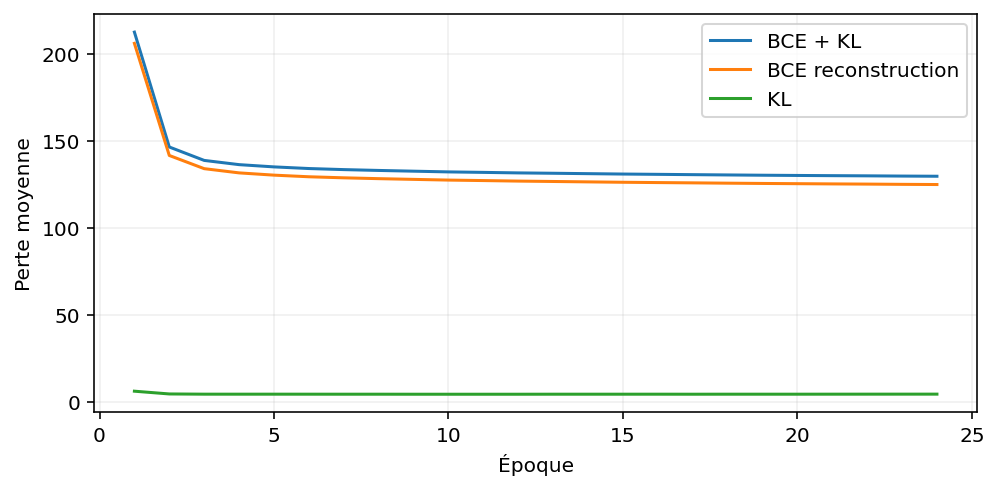

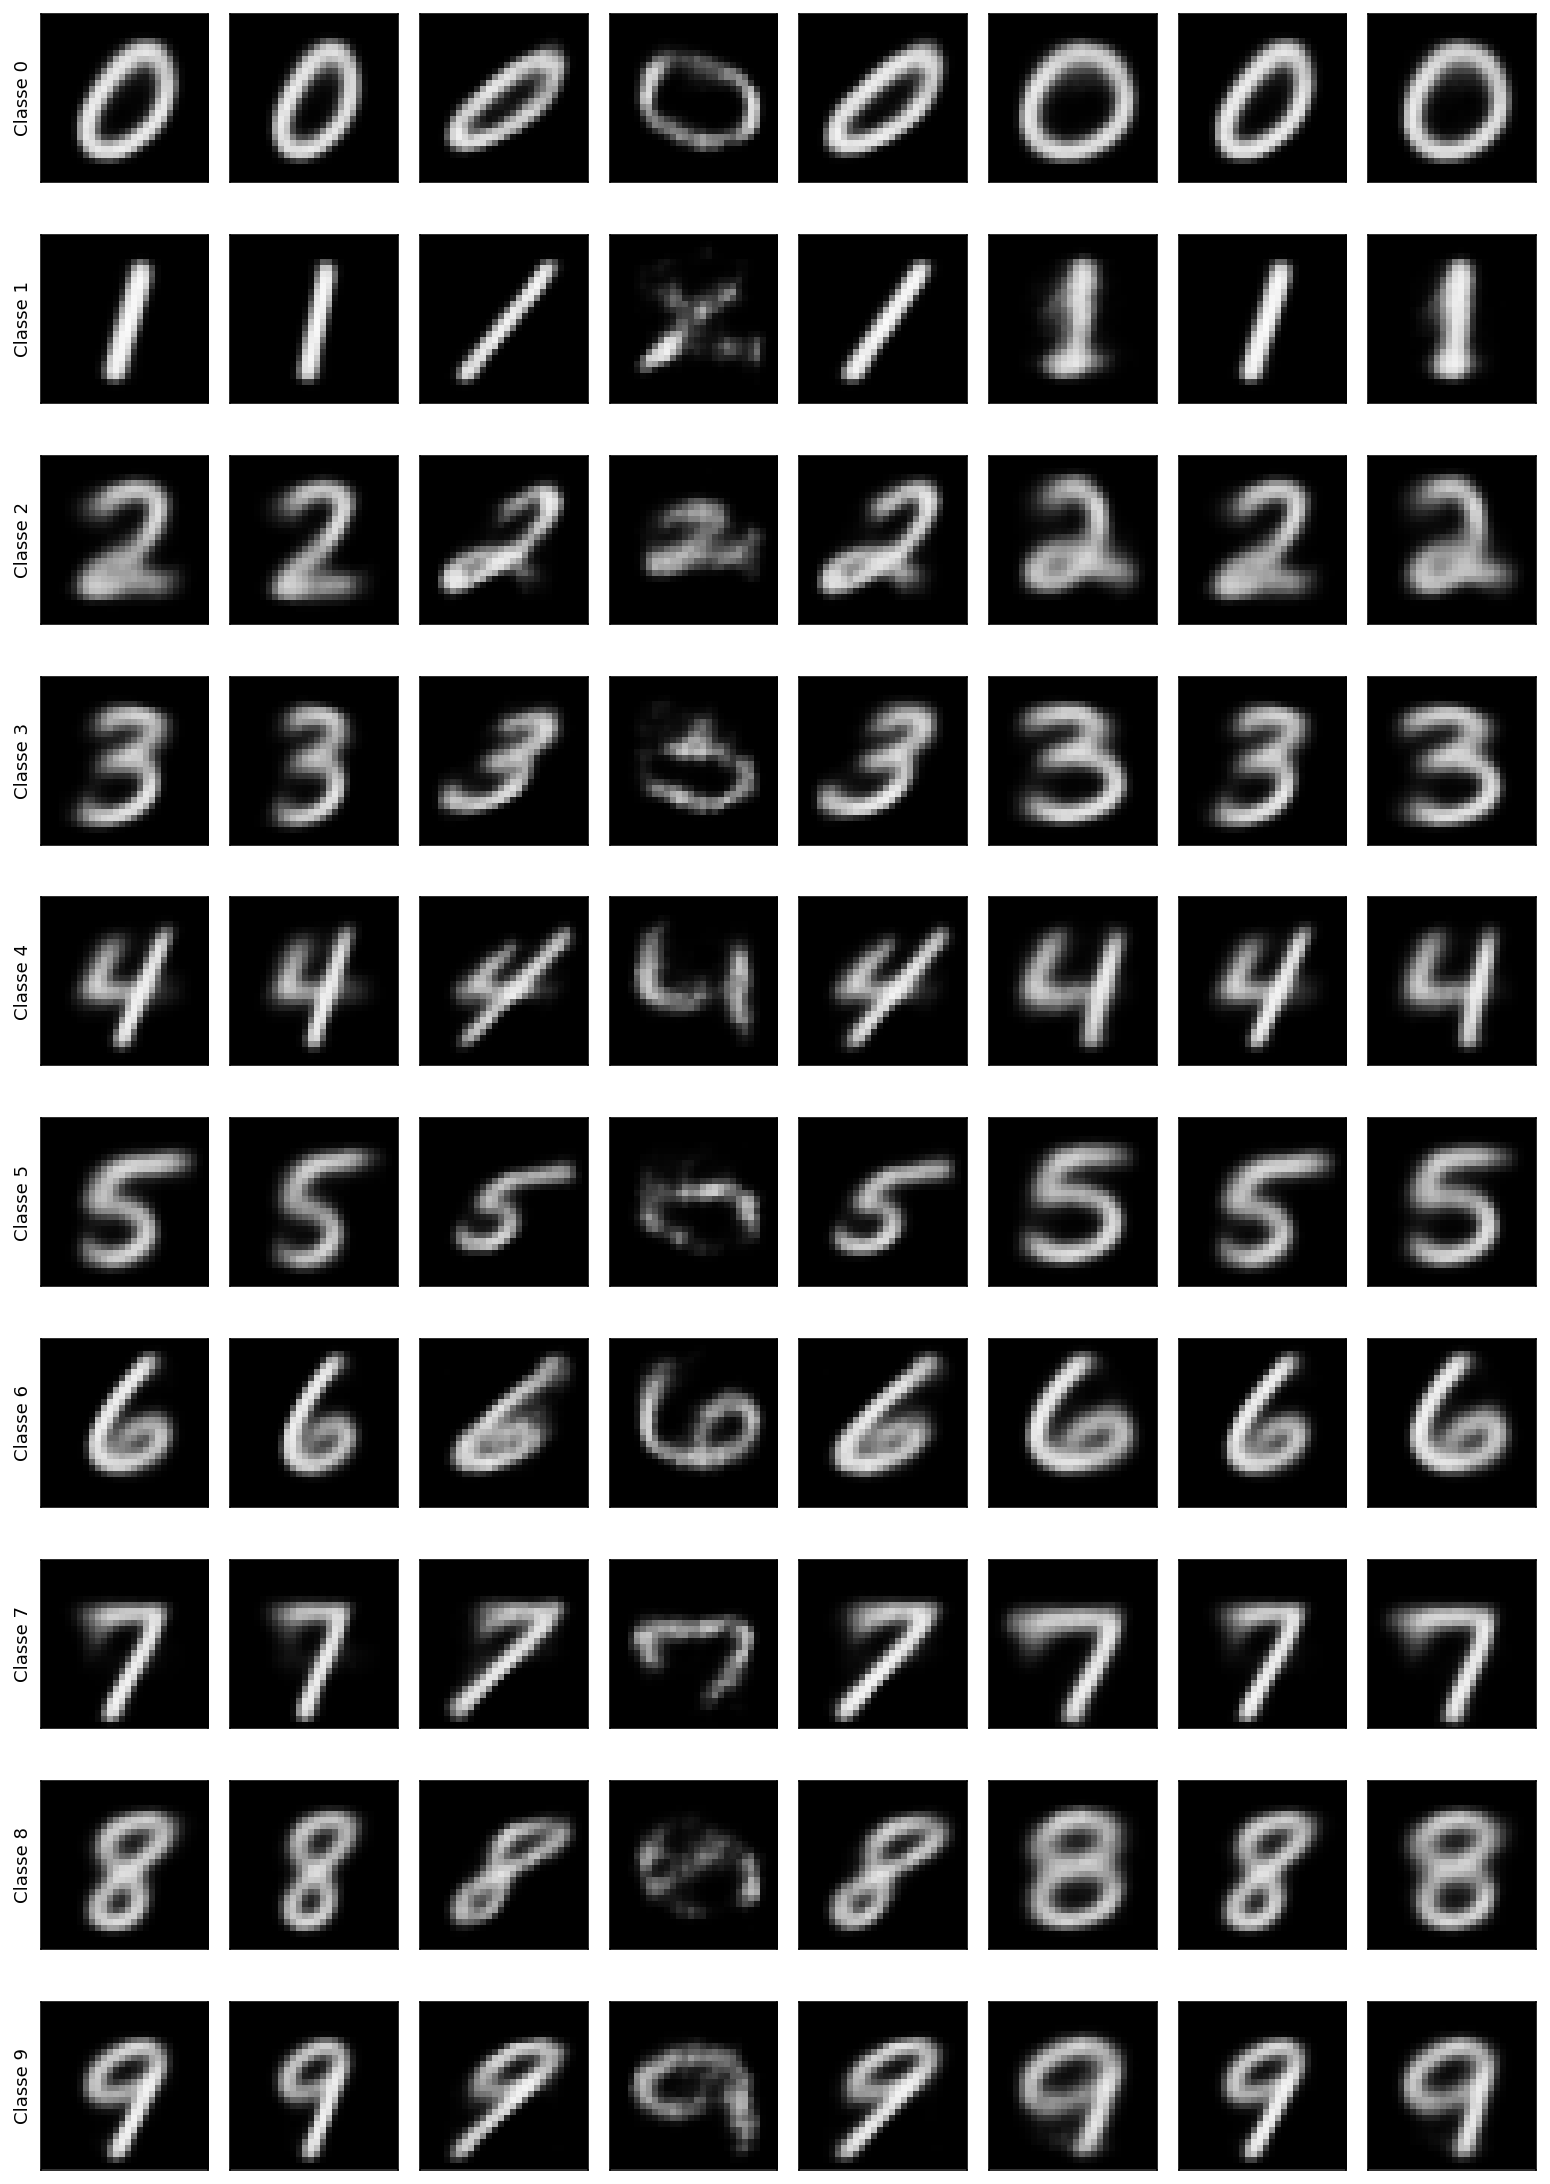

In [6]:
# Limiter z à 2 dimensions encourage le décodeur à utiliser la classe y.
# Avec z=16, un essai initial montrait des classes parfois ignorées.
cvae=train_vae(VAE(conditional=True,latent=2),ml,'CVAE',epochs=24)
curves(histories['CVAE'],'16_CVAE_pertes')
with torch.no_grad():
    common_z=torch.randn(8,cvae.latent,device=device)
    rows=[cvae.decode(common_z,torch.full((8,),digit,device=device,dtype=torch.long)).cpu() for digit in range(10)]
    grid(rows,[f'Classe {k}' for k in range(10)],'17_CVAE_classes')
metrics['CVAE_last_train']=histories['CVAE'][-1]

### Réponses C
1. Le CVAE fournit une variable explicite y pour choisir la classe ; le VAE
standard ne possède pas ce bouton de contrôle.
2. Si y est absent ou ignoré, le modèle peut mélanger les classes et ne pas suivre
la consigne. L'injection dans les deux réseaux favorise un apprentissage cohérent.
3. Non : il faut aussi tester la conformité à y et la diversité. Ici la grille
permet une inspection qualitative ; elle ne constitue pas une précision mesurée.

## Bloc D — PixelCNN : prédire uniquement à partir des pixels précédents
On conserve les 256 niveaux de gris du PDF. Le premier masque A exclut le pixel
courant ; les masques B autorisent sa représentation cachée, déjà causale.
Trois couches B suivent la couche A de noyau 7. Aucun BatchNorm ne mélange les
positions. L'entraînement utilise 12 000 images d'apprentissage, sans images test.
Ce sous-ensemble et le modèle compact limitent le temps ; la qualité n'est pas
celle d'un PixelCNN longuement entraîné sur les 60 000 images.

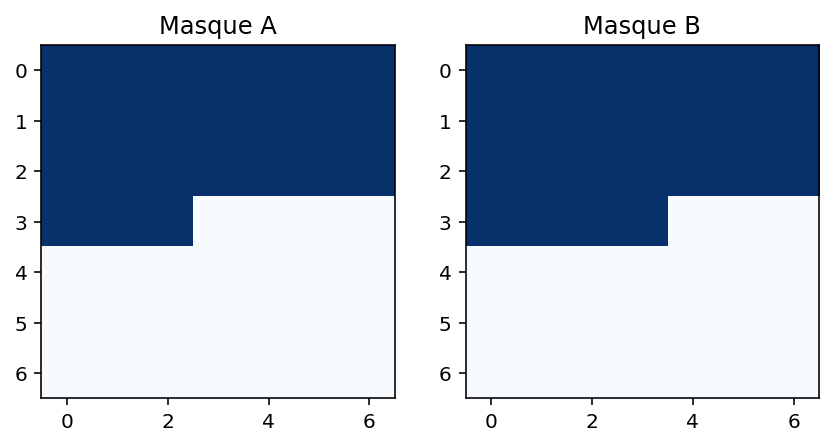

Test causalité : différence maximale = 0.0


PixelCNN époque 1 / 10 {'CE nats/pixel': 4.229532948811849}


PixelCNN époque 2 / 10 {'CE nats/pixel': 2.9669802494049073}


PixelCNN époque 3 / 10 {'CE nats/pixel': 2.7002242170969644}


PixelCNN époque 4 / 10 {'CE nats/pixel': 2.604903911590576}


PixelCNN époque 5 / 10 {'CE nats/pixel': 2.550726205825806}


PixelCNN époque 6 / 10 {'CE nats/pixel': 2.5132702198028563}


PixelCNN époque 7 / 10 {'CE nats/pixel': 2.4899998264312746}


PixelCNN époque 8 / 10 {'CE nats/pixel': 2.470517832438151}


PixelCNN époque 9 / 10 {'CE nats/pixel': 2.45756902440389}


PixelCNN époque 10 / 10 {'CE nats/pixel': 2.4437068614959716}


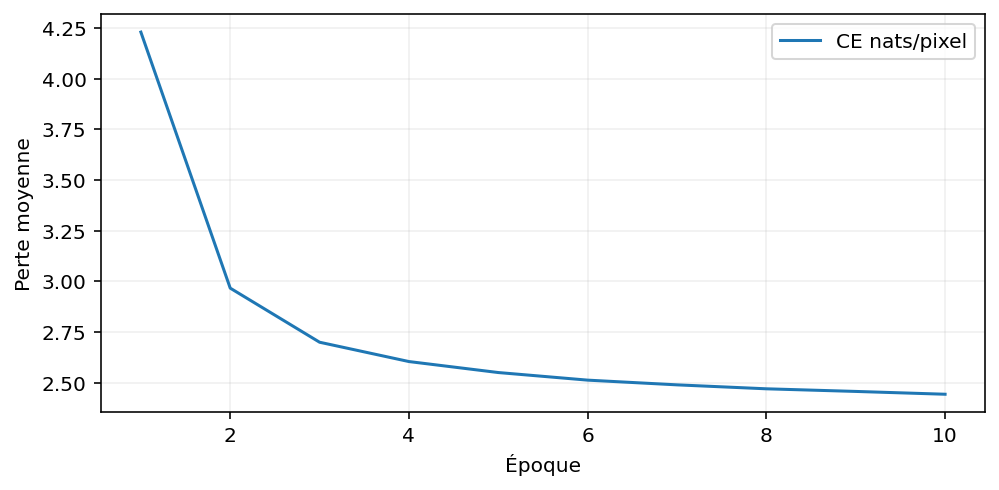

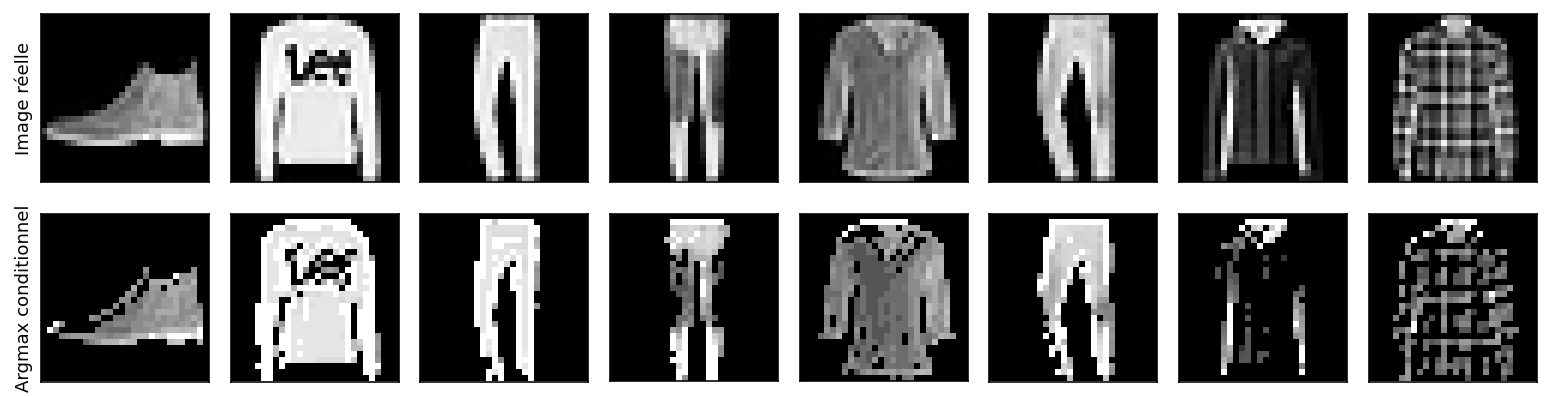

Génération PixelCNN : ligne 7 /28


Génération PixelCNN : ligne 14 /28


Génération PixelCNN : ligne 21 /28


Génération PixelCNN : ligne 28 /28


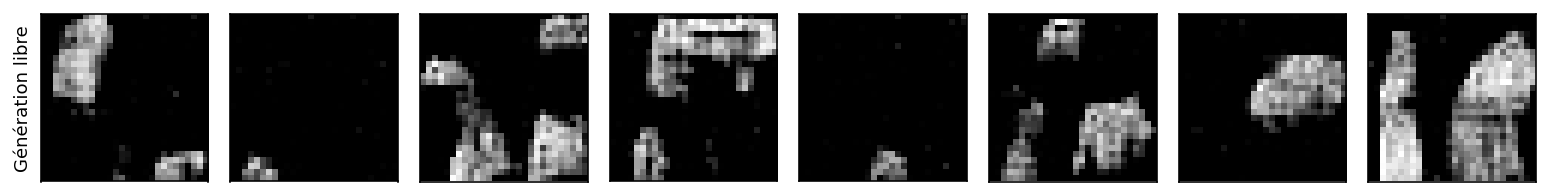

Test PixelCNN : 3.5326185980046665 bits/pixel
Durée génération 8 images : 1.8599939346313477 secondes


In [7]:
class MaskedConv2d(nn.Conv2d):
    def __init__(self,mask_type,*args,**kwargs):
        super().__init__(*args,**kwargs)
        assert mask_type in ('A','B');mask=torch.ones_like(self.weight)
        # Supprimer les lignes futures et la droite du pixel central.
        h,w=self.kernel_size;mask[:,:,h//2+1:,:]=0
        mask[:,:,h//2,w//2+(1 if mask_type=='B' else 0):]=0
        self.register_buffer('mask',mask)
    def forward(self,x):
        # Multiplier dans le graphe : les connexions interdites restent nulles.
        return F.conv2d(x,self.weight*self.mask,self.bias,self.stride,self.padding,self.dilation,self.groups)
class PixelCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net=nn.Sequential(MaskedConv2d('A',1,32,7,padding=3),nn.ReLU(),MaskedConv2d('B',32,32,3,padding=1),nn.ReLU(),MaskedConv2d('B',32,32,3,padding=1),nn.ReLU(),MaskedConv2d('B',32,32,3,padding=1),nn.ReLU(),nn.Conv2d(32,256,1))
    def forward(self,x):return self.net(x)
pixel=PixelCNN().to(device)
fig,axes=plt.subplots(1,2,figsize=(6,3))
for ax,kind in zip(axes,['A','B']):
    mask=MaskedConv2d(kind,1,1,7,padding=3).mask[0,0].cpu()
    ax.imshow(mask,cmap='Blues',vmin=0,vmax=1);ax.set_title('Masque '+kind)
savefig('18_masques')

# Vérifier la causalité par une perturbation : changer le pixel courant et tous
# les suivants ne doit pas modifier les logits du pixel courant.
pixel.eval()
with torch.no_grad():
    a=ft[:1].to(device);b=a.clone();b[:,:,14,14:]=1-b[:,:,14,14:];b[:,:,15:,:]=1-b[:,:,15:,:]
    diff=(pixel(a)[:,:,14,14]-pixel(b)[:,:,14,14]).abs().max().item()
assert diff<1e-6
print('Test causalité : différence maximale =',diff)
metrics['PixelCNN_causality_max_difference']=diff

# L'entropie croisée reçoit des logits [B,256,28,28] et des cibles entières.
# Les intensités d'entrée restent normalisées ; seules les cibles sont 0–255.
selection=torch.randperm(len(fx),generator=torch.Generator().manual_seed(42))[:12000]
pl=DataLoader(TensorDataset(fx[selection],fy[selection]),batch_size=128,shuffle=True)
opt=torch.optim.Adam(pixel.parameters(),lr=1e-3);hist=[]
for ep in range(10):
    pixel.train();total=0
    for x,_ in pl:
        x=x.to(device);target=(x[:,0]*255).round().long()
        # Oublier les gradients précédents, puis prédire 256 scores par position.
        opt.zero_grad(set_to_none=True)
        # L'entropie croisée favorise la vraie intensité parmi les 256 possibilités.
        loss=F.cross_entropy(pixel(x),target)
        # Calculer les gradients et mettre à jour uniquement les connexions autorisées.
        loss.backward();opt.step()
        # Accumuler une moyenne pondérée par le nombre d'images.
        total+=loss.item()*len(x)
    row={'CE nats/pixel':total/len(selection)};hist.append(row)
    print('PixelCNN époque',ep+1,'/ 10',row,flush=True)
histories['PixelCNN']=hist;curves(hist,'19_PixelCNN_perte');pixel.eval()
torch.save(pixel.state_dict(),ROOT/'models'/'PixelCNN.pt')
with torch.no_grad():
    # Prédiction avec contexte réel : chaque position voit le préfixe de l'image
    # réelle. Ce résultat n'est PAS une génération libre ni une reconstruction AE.
    logits=pixel(ft[:8].to(device));pred=logits.argmax(1).float().unsqueeze(1)/255
    grid([ft[:8],pred],['Image réelle','Argmax conditionnel'],'20_PixelCNN_predictions')
    total=0
    for x in ft.split(128):
        x=x.to(device);total+=F.cross_entropy(pixel(x),(x[:,0]*255).round().long()).item()*len(x)
metrics['PixelCNN_test_nats_per_pixel']=total/len(ft)
metrics['PixelCNN_test_bits_per_pixel']=total/len(ft)/np.log(2)

# Générer vraiment : commencer avec des zéros, puis tirer chaque pixel depuis les
# probabilités prédites. Les nouveaux pixels deviennent le contexte des suivants.
# 784 passes avant sont nécessaires même pour une petite grille de 8 images.
sample_start=time.time()
with torch.no_grad():
    generated=torch.zeros(8,1,28,28,device=device)
    for row in range(28):
        for col in range(28):
            logits=pixel(generated)[:,:,row,col]
            value=torch.multinomial(torch.softmax(logits,dim=1),1).squeeze(1)
            generated[:,0,row,col]=value.float()/255
        if (row+1)%7==0:print('Génération PixelCNN : ligne',row+1,'/28',flush=True)
    grid([generated],['Génération libre'],'21_PixelCNN_generation')
metrics['PixelCNN_generation_seconds_8_images']=time.time()-sample_start
print('Test PixelCNN :',metrics['PixelCNN_test_bits_per_pixel'],'bits/pixel')
print('Durée génération 8 images :',metrics['PixelCNN_generation_seconds_8_images'],'secondes')

### Réponses D
1. Le masque A interdit de voir le pixel à prédire. Les couches B ne manipulent
que des caractéristiques déjà causales ; les pixels futurs restent inaccessibles.
2. Le pixel suivant dépend de ceux déjà tirés. L'entraînement prédit toutes les
positions en parallèle grâce aux masques ; la génération reste séquentielle.
3. PixelCNN optimise directement une vraisemblance discrète, sans encodeur latent
ni KL. Son échantillonnage est coûteux. Un VAE génère toute l'image en une passe,
offre un espace latent manipulable, mais optimise une borne et peut lisser les détails.

## Bilan et preuves
AE : reconstruction déterministe. DAE : suppression du bruit appris.
VAE : génération à partir d'un prior. CVAE : génération guidée par une classe.
PixelCNN : factorisation causale et échantillonnage pixel par pixel.
Les pertes AE, VAE et PixelCNN ont des unités différentes et ne doivent pas être
comparées directement comme s'il s'agissait du même score.
Les commentaires théoriques ci-dessus ne remplacent pas l'inspection des figures.

In [8]:
# Sauvegarder les mesures et les conditions exactes pour pouvoir vérifier le travail.
metrics['seconds_total']=time.time()-started
metrics['protocol']={'seed':42,'AE_epochs':10,'DAE_epochs':10,'VAE_epochs':12,'CVAE_epochs':24,'CVAE_latent_dimension':2,'PixelCNN_epochs':10,'PixelCNN_train_count':12000,'AE_VAE_train_count':60000,'test_count':10000,'device':str(device),'torch':torch.__version__}
assert all(np.isfinite(row['CE nats/pixel']) for row in histories['PixelCNN'])
assert all(np.isfinite(v) for name,hist in histories.items() for row in hist for v in row.values())
assert tuple(dense_rec.shape)==(8,1,28,28)
assert len(list((ROOT/'models').glob('*.pt')))==6
(ROOT/'metrics.json').write_text(json.dumps(metrics,indent=2,ensure_ascii=False),encoding='utf-8')
(ROOT/'histories.json').write_text(json.dumps(histories,indent=2,ensure_ascii=False),encoding='utf-8')
print(json.dumps(metrics,indent=2,ensure_ascii=False))
print('TERMINÉ : 6 modèles entraînés, figures sauvegardées, pertes finies, causalité vérifiée.')

{
  "AE_dense_test_MSE": 0.010390885211010368,
  "AE_conv_test_MSE": 0.00526549266406468,
  "debruitage": [
    {
      "sigma": 0,
      "AE_conv_MSE": 0.00526549266406468,
      "DAE_MSE": 0.008617430223737444
    },
    {
      "sigma": 0.1,
      "AE_conv_MSE": 0.00788271238365952,
      "DAE_MSE": 0.0083142812942972
    },
    {
      "sigma": 0.3,
      "AE_conv_MSE": 0.022464164453623245,
      "DAE_MSE": 0.009062609637513453
    },
    {
      "sigma": 0.5,
      "AE_conv_MSE": 0.04539314422607422,
      "DAE_MSE": 0.017737309794523277
    }
  ],
  "VAE_last_train": {
    "BCE + KL": 241.26715657552083,
    "BCE reconstruction": 223.70482517903645,
    "KL": 17.56233157043457
  },
  "CVAE_last_train": {
    "BCE + KL": 129.9115512532552,
    "BCE reconstruction": 125.15295286865235,
    "KL": 4.758598508961995
  },
  "PixelCNN_causality_max_difference": 0.0,
  "PixelCNN_test_nats_per_pixel": 2.4486246212005613,
  "PixelCNN_test_bits_per_pixel": 3.5326185980046665,
  "PixelCNN_g

## Lecture des résultats mesurés

**AE dense et convolutionnel.** La MSE test passe de 0.010391
à 0.005265. Pour ce protocole, le convolutionnel reconstruit
mieux selon cette mesure. Cela ne prouve pas qu'il gagne pour toute architecture.

**Débruitage.** Avec σ = 0,3, l'AE propre a une MSE de
0.022464, contre 0.009063
pour le DAE. Sur les images propres, le DAE est moins bon : l'apprentissage
spécialisé du bruit impose donc un compromis visible.

**VAE et CVAE.** Les courbes séparent BCE et KL. Les générations VAE viennent
du prior, les générations CVAE utilisent en plus le one-hot choisi. La grille CVAE
sert à vérifier visuellement le conditionnement, sans prétendre mesurer une précision.

**PixelCNN.** Le test causal donne une différence maximale de
0. La perte test est de
3.5326 bits/pixel. Les 8 générations libres ont pris
1.9 secondes. Le résultat avec contexte
réel peut être plus convaincant que la génération libre : les erreurs se propagent
pendant l'échantillonnage. Inspecter les deux grilles séparément.

Les six modèles ont été entraînés ; β-VAE reste une extension optionnelle non réalisée.
